In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df=pd.read_csv("Operating_room_utilization_dataset.csv")

In [ ]:
df.sample(5)

,index,Encounter ID,Date,OR Suite,Service,CPT Code,CPT Description,Booked Time (min),OR Schedule,Wheels In,Start Time,End Time,Wheels Out
1362,1362,11363,03/01/22,2,Orthopedics,64721,"Carpal tunnel release, open",60,03/01/22 08:15 AM,03/01/22 08:42 AM,03/01/22 09:04 AM,03/01/22 09:38 AM,03/01/22 09:50 AM
851,851,10852,02/07/22,6,Plastic,14060,"Adjacent tissue transfer, eyelids, nose, ears,...",120,02/07/22 09:15 AM,02/07/22 09:22 AM,02/07/22 09:45 AM,02/07/22 10:40 AM,02/07/22 10:55 AM
1402,1402,11403,03/02/22,3,Pediatrics,69421,"Myringotomy, general anesthesia",60,03/02/22 10:45 AM,03/02/22 11:59 AM,03/02/22 12:11 PM,03/02/22 12:39 PM,03/02/22 12:51 PM
1724,1724,11725,03/15/22,3,Ophthalmology,66982,Extracapsular cataract removal,45,03/15/22 08:00 AM,03/15/22 08:00 AM,03/15/22 08:12 AM,03/15/22 08:30 AM,03/15/22 08:41 AM
2159,2159,12160,03/31/22,5,ENT,42826,Tonsillectomy,60,03/31/22 01:00 PM,03/31/22 02:05 PM,03/31/22 02:28 PM,03/31/22 03:00 PM,03/31/22 03:10 PM


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2172 entries, 0 to 2171
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   index              2172 non-null   int64 
 1   Encounter ID       2172 non-null   int64 
 2   Date               2172 non-null   object
 3   OR Suite           2172 non-null   int64 
 4   Service            2172 non-null   object
 5   CPT Code           2172 non-null   int64 
 6   CPT Description    2172 non-null   object
 7   Booked Time (min)  2172 non-null   int64 
 8   OR Schedule        2172 non-null   object
 9   Wheels In          2172 non-null   object
 10  Start Time         2172 non-null   object
 11  End Time           2172 non-null   object
 12  Wheels Out         2172 non-null   object
dtypes: int64(5), object(8)
memory usage: 220.7+ KB


In [ ]:
df["Date"]=pd.to_datetime(df["Date"])
df["OR Schedule"]=pd.to_datetime(df["OR Schedule"])
df["Wheels In"]=pd.to_datetime(df["Wheels In"])
df["Start Time"]=pd.to_datetime(df["Start Time"])
df["End Time"]=pd.to_datetime(df["End Time"])
df["Wheels Out"]=pd.to_datetime(df["Wheels Out"])

<ipython-input-12-c5274a12dc92>:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["OR Schedule"]=pd.to_datetime(df["OR Schedule"])
<ipython-input-12-c5274a12dc92>:3: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["Wheels In"]=pd.to_datetime(df["Wheels In"])
<ipython-input-12-c5274a12dc92>:4: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["Start Time"]=pd.to_datetime(df["Start Time"])
<ipython-input-12-c5274a12dc92>:5: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-exp

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2172 entries, 0 to 2171
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   index              2172 non-null   int64         
 1   Encounter ID       2172 non-null   int64         
 2   Date               2172 non-null   datetime64[ns]
 3   OR Suite           2172 non-null   int64         
 4   Service            2172 non-null   object        
 5   CPT Code           2172 non-null   int64         
 6   CPT Description    2172 non-null   object        
 7   Booked Time (min)  2172 non-null   int64         
 8   OR Schedule        2172 non-null   datetime64[ns]
 9   Wheels In          2172 non-null   datetime64[ns]
 10  Start Time         2172 non-null   datetime64[ns]
 11  End Time           2172 non-null   datetime64[ns]
 12  Wheels Out         2172 non-null   datetime64[ns]
dtypes: datetime64[ns](6), int64(5), object(2)
memory usage: 220.7+ 

In [ ]:
df["OR Suite"]=df["OR Suite"].astype("object")

# Calculate time differences
df['OR Schedule to Wheels In'] = (df['Wheels In'] - df['OR Schedule']).dt.total_seconds() / 60
df['Wheels In to Start Time'] = (df['Start Time'] - df['Wheels In']).dt.total_seconds() / 60
df['Start Time to End Time'] = (df['End Time'] - df['Start Time']).dt.total_seconds() / 60
df['End Time to Wheels Out'] = (df['Wheels Out'] - df['End Time']).dt.total_seconds() / 60


In [ ]:
df.describe(include="object")

,OR Suite,Service,CPT Description
count,2172,2172,2172
unique,8,10,32
top,3,Ophthalmology,Extracapsular cataract removal
freq,439,334,334


In [ ]:
# Overall Utilization
total_booked_time = df['Booked Time (min)'].sum()
total_actual_time = df['Start Time to End Time'].sum()
overall_utilization_rate = total_actual_time / total_booked_time
overall_utilization_rate

0.5891384092332469

In [ ]:
# Weekly Utilization
df['Week'] = df['Date'].dt.isocalendar().week
weekly_utilization = df.groupby('Week')['Start Time to End Time'].sum() / df.groupby('Week')['Booked Time (min)'].sum()
weekly_utilization


Week
1     0.591547
2     0.589389
3     0.593664
4     0.589267
5     0.587790
6     0.586562
7     0.592404
8     0.587804
9     0.587588
10    0.584793
11    0.589899
12    0.591667
13    0.586594
dtype: float64

In [ ]:
# prompt: how to isolate month from the data

import pandas as pd
df['Month'] = pd.to_datetime(df['Date']).dt.month
monthly_utilization = df.groupby('Month')['Start Time to End Time'].sum() / df.groupby('Month')['Booked Time (min)'].sum()
monthly_utilization


Month
1    0.590718
2    0.588235
3    0.588542
dtype: float64

In [ ]:
# Identify Workflow Delays
workflow_delays = df[['OR Schedule to Wheels In', 'Wheels In to Start Time', 'Start Time to End Time', 'End Time to Wheels Out']].describe()
workflow_delays


,OR Schedule to Wheels In,Wheels In to Start Time,Start Time to End Time,End Time to Wheels Out
count,2172.000000,2172.000000,2172.000000,2172.000000
mean,35.542818,21.529926,45.475138,12.691989
std,37.932126,6.416851,26.742297,2.667420
min,-55.000000,3.000000,12.000000,3.000000
25%,5.000000,18.000000,28.000000,11.000000
50%,25.000000,23.000000,35.000000,13.000000
75%,58.000000,25.000000,58.000000,14.000000
max,210.000000,45.000000,136.000000,21.000000


In [ ]:
# Booking Time Accuracy
df['Booking Accuracy'] = df['Booked Time (min)'] - df['Start Time to End Time']
booking_accuracy_by_service = df.groupby('Service')['Booking Accuracy'].describe()
booking_accuracy_by_service


,count,mean,std,min,25%,50%,75%,max
Service,,,,,,,,
ENT,197.0,33.060914,3.595114,28.0,30.00,33.0,36.0,38.0
General,117.0,30.000000,9.131227,20.0,20.00,28.0,42.0,42.0
OBGYN,164.0,42.250000,1.303017,40.0,42.25,43.0,43.0,43.0
Ophthalmology,334.0,28.338323,2.926922,14.0,27.00,27.0,31.0,31.0
Orthopedics,321.0,29.205607,7.224185,12.0,24.00,29.0,35.0,43.0
Pediatrics,220.0,29.800000,2.567091,26.0,28.00,30.0,32.0,33.0
Plastic,207.0,41.415459,17.673175,15.0,26.00,44.0,52.0,72.0
Podiatry,246.0,33.223577,31.884018,-3.0,18.00,23.0,30.0,128.0
Urology,193.0,29.523316,6.533625,21.0,24.00,30.0,33.0,40.0


In [ ]:
# Cancellations
cancellations = df[df['Wheels In'].isna()]
cancellations


,index,Encounter ID,Date,OR Suite,Service,CPT Code,CPT Description,Booked Time (min),OR Schedule,Wheels In,Start Time,End Time,Wheels Out,Operation_time,OR Schedule to Wheels In,Wheels In to Start Time,Start Time to End Time,End Time to Wheels Out,Week,Booking Accuracy


In [ ]:
# Specialty and Procedure Variations
specialty_workflow = df.groupby(['Service', 'CPT Code'])[['OR Schedule to Wheels In', 'Wheels In to Start Time', 'Start Time to End Time', 'End Time to Wheels Out']].mean()

specialty_workflow

OR Schedule to Wheels In  Wheels In to Start Time  \
Service       CPT Code                                                      
ENT           30520                    17.500000                21.500000   
              42826                    33.192053                23.112583   
General       43775                    20.500000                20.000000   
              47562                    60.000000                19.000000   
OBGYN         57460                    26.000000                25.000000   
              58562                    18.000000                21.500000   
Ophthalmology 66982                    -3.673653                10.823353   
Orthopedics   26045                    58.000000                24.000000   
              26356                   103.000000                21.000000   
              26735                    83.000000                25.761905   
              27130                    70.000000                32.000000   
              27445                    27.353659                36.853659   
              29877                    89.455357                25.339286   
              64721                    16.000000                22.500000   
Pediatrics    69421                    77.000000                19.500000   
              69436                    25.666667                24.333333   
Plastic       14060                    16.325581                22.534884   
              15773                    17.500000                21.000000   
              17110                    16.000000                19.666667   
              30400                    14.000000                26.000000   
Podiatry      28055                    63.000000                25.000000   
              28060                    21.000000                24.500000   
              28110                     5.000000                27.000000   
              28285                    60.000000                22.500000   
              28289                    38.000000                25.000000   
              28296                    56.141176                23.529412   
              28297                   110.000000                30.000000   
Urology       52353                    81.684211                22.802632   
              55250                    46.307692                18.961538   
              55873                    24.000000                23.000000   
Vascular      28820                    14.884615                21.615385   
              36901                    82.126316                24.568421   

                        Start Time to End Time  End Time to Wheels Out  
Service       CPT Code                                                  
ENT           30520                  52.500000               12.000000  
              42826                  28.291391               12.543046  
General       43775                  96.000000               13.500000  
              47562                  48.000000               13.000000  
OBGYN         57460                  33.500000               13.500000  
              58562                  77.000000               13.000000  
Ophthalmology 66982                  16.302395                8.745509  
Orthopedics   26045                  56.000000               11.904762  
              26356                  47.000000               19.000000  
              26735                  84.000000               17.000000  
              27130                  88.000000               18.000000  
              27445                  90.170732               16.060976  
              29877                  34.696429               13.437500  
              64721                  35.500000               12.000000  
Pediatrics    69421                  27.500000               13.000000  
              69436                  32.000000               13.666667  
Plastic       14060                  75.453488               14.023256  
              1577

In [ ]:
specialty_booking_accuracy = df.groupby(['Service', 'CPT Code'])['Booking Accuracy'].mean()
specialty_booking_accuracy

Service        CPT Code
ENT            30520        37.500000
               42826        31.708609
General        43775        24.000000
               47562        42.000000
OBGYN          57460        41.500000
               58562        43.000000
Ophthalmology  66982        28.338323
Orthopedics    26045        34.000000
               26356        43.000000
               26735        36.000000
               27130        32.000000
               27445        29.829268
               29877        25.303571
               64721        24.500000
Pediatrics     69421        32.500000
               69436        28.000000
Plastic        14060        44.546512
               15773        58.000000
               17110        27.333333
               30400        48.000000
Podiatry       28055        12.000000
               28060        25.500000
               28110        -3.000000
               28285        15.000000
               28289        18.000000
               28296      

In [ ]:
specialty_cancellation_rates = cancellations.groupby(['Service', 'CPT Code']).size() / df.groupby(['Service', 'CPT Code']).size()
specialty_cancellation_rates

Service        CPT Code
ENT            30520      NaN
               42826      NaN
General        43775      NaN
               47562      NaN
OBGYN          57460      NaN
               58562      NaN
Ophthalmology  66982      NaN
Orthopedics    26045      NaN
               26356      NaN
               26735      NaN
               27130      NaN
               27445      NaN
               29877      NaN
               64721      NaN
Pediatrics     69421      NaN
               69436      NaN
Plastic        14060      NaN
               15773      NaN
               17110      NaN
               30400      NaN
Podiatry       28055      NaN
               28060      NaN
               28110      NaN
               28285      NaN
               28289      NaN
               28296      NaN
               28297      NaN
Urology        52353      NaN
               55250      NaN
               55873      NaN
Vascular       28820      NaN
               36901      NaN
dtype: float64

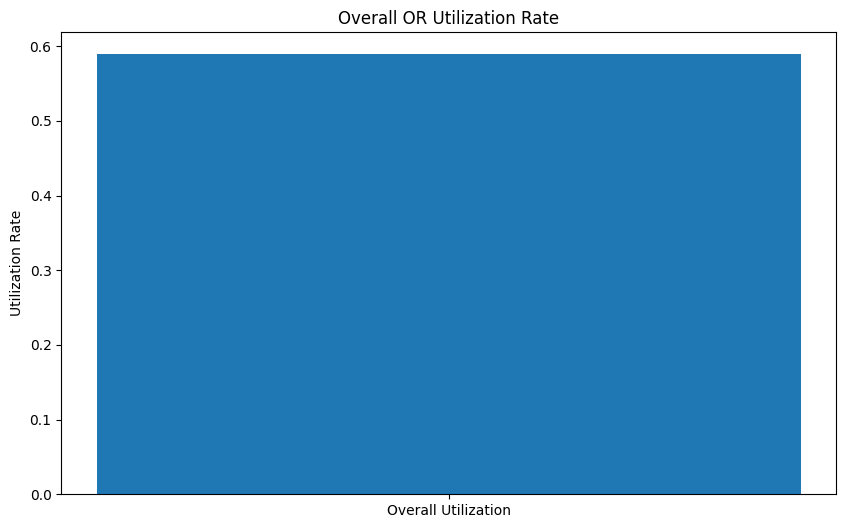

In [ ]:
# Overall Utilization Rate
plt.figure(figsize=(10, 6))
plt.bar(['Overall Utilization'], [overall_utilization_rate])
plt.title('Overall OR Utilization Rate')
plt.ylabel('Utilization Rate')
plt.show()

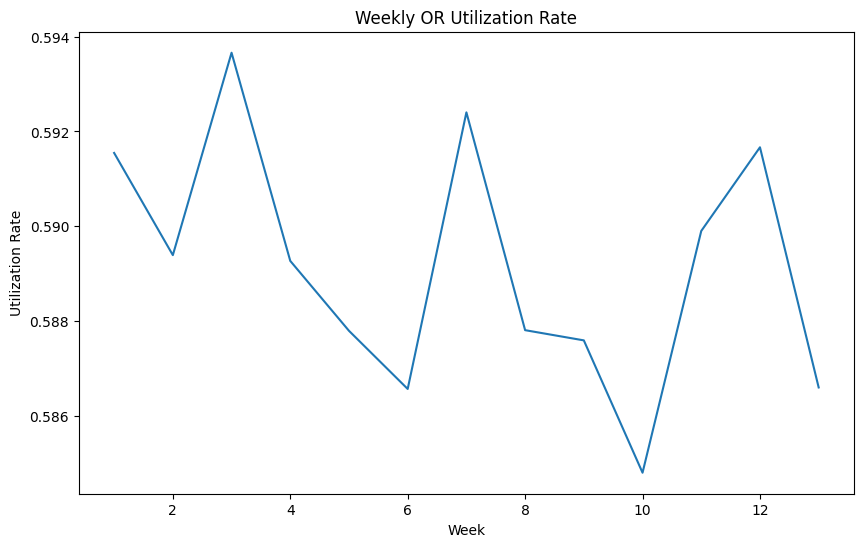

In [ ]:

# Weekly Utilization
plt.figure(figsize=(10, 6))
sns.lineplot(data=weekly_utilization)
plt.title('Weekly OR Utilization Rate')
plt.ylabel('Utilization Rate')
plt.xlabel('Week')
plt.show()

<Figure size 1200x800 with 0 Axes>

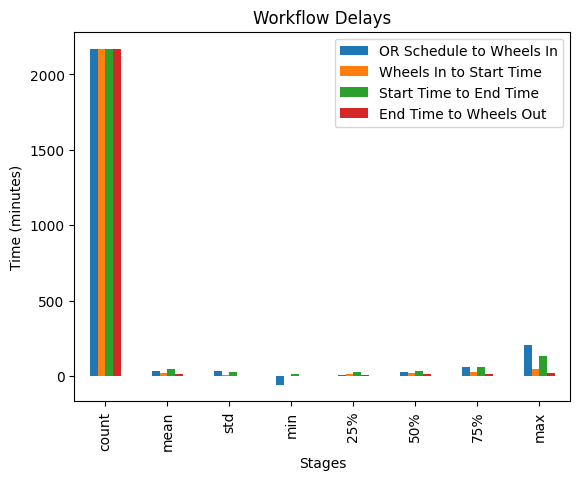

In [ ]:
# Workflow Delays
plt.figure(figsize=(12, 8))
workflow_delays.plot(kind='bar')
plt.title('Workflow Delays')
plt.ylabel('Time (minutes)')
plt.xlabel('Stages')
plt.show()


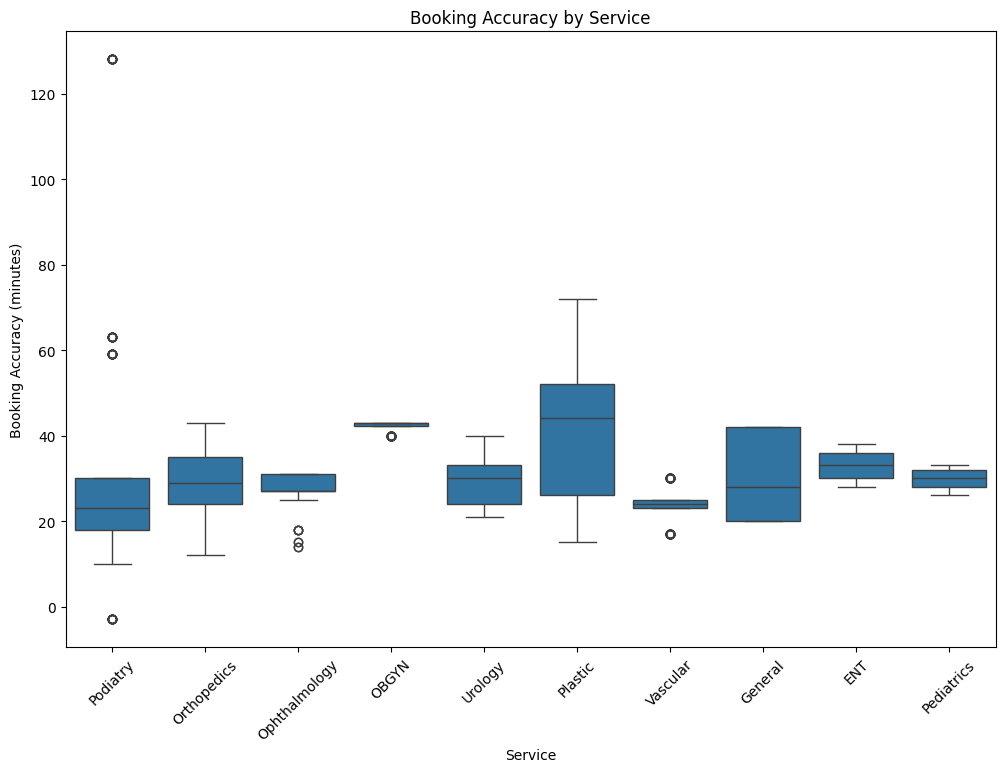

In [ ]:
# Booking Accuracy by Service
plt.figure(figsize=(12, 8))
sns.boxplot(x='Service', y='Booking Accuracy', data=df)
plt.title('Booking Accuracy by Service')
plt.ylabel('Booking Accuracy (minutes)')
plt.xlabel('Service')
plt.xticks(rotation=45)
plt.show()

<ipython-input-59-7b8e464b274a>:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=avg_time_per_service, x='Start Time to End Time', y='Service', palette='viridis')


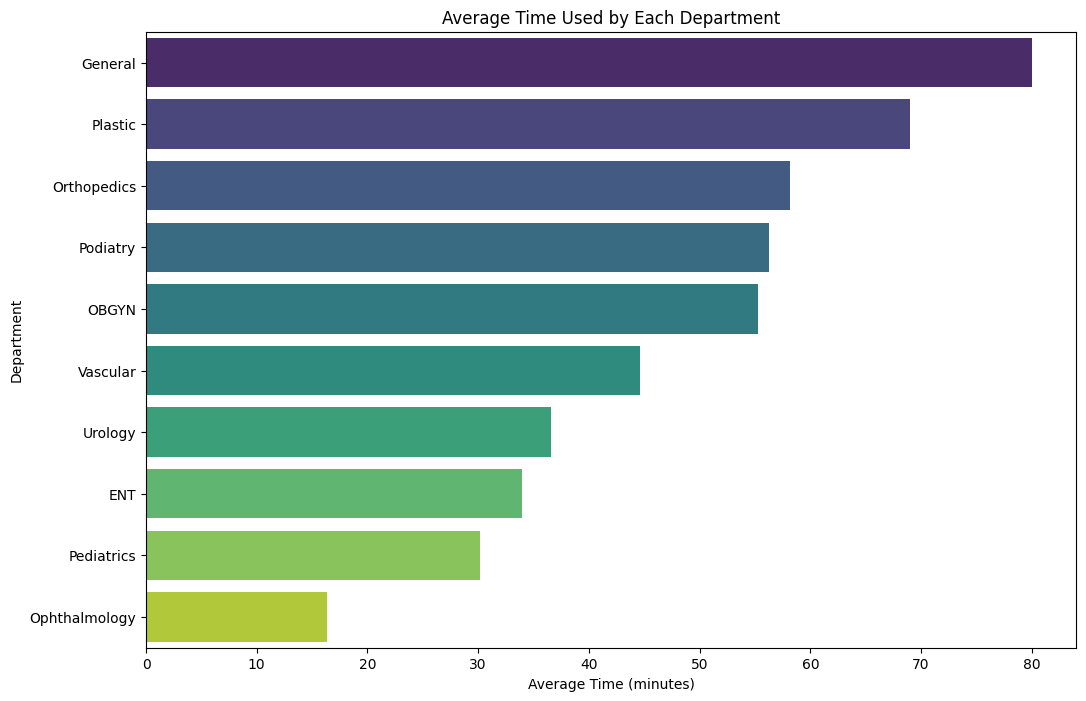

In [ ]:
# Calculate the average time from 'Start Time' to 'End Time' for each department
avg_time_per_service = df.groupby('Service')['Start Time to End Time'].mean().reset_index()

# Sort the values for better visualization
avg_time_per_service = avg_time_per_service.sort_values(by='Start Time to End Time', ascending=False)

# Plot the average time used by each department
plt.figure(figsize=(12, 8))
sns.barplot(data=avg_time_per_service, x='Start Time to End Time', y='Service', palette='viridis')
plt.title('Average Time Used by Each Department')
plt.xlabel('Average Time (minutes)')
plt.ylabel('Department')
plt.show()


**Conclusions:**

**Overall Utilization Rate:**

The overall utilization rate of the operating rooms is approximately 58.9%. This indicates that the operating rooms are being used for 58.9% of the time that they are booked.

**Weekly Utilization:**

The weekly utilization rate varies slightly but stays within the range of approximately 58.4% to 59.3%. This consistency indicates that there are no major fluctuations in weekly usage.

**Monthly Utilization:**

The monthly utilization rates for the first three months are fairly consistent, ranging from approximately 58.8% to 59.1%.

**Workflow Delays:**

There are notable delays at various stages of the workflow:

The average time from OR Schedule to Wheels In is approximately 35.5 minutes.

The average time from Wheels In to Start Time is approximately 21.5 minutes.

The average time from Start Time to End Time is approximately 45.5 minutes.

The average time from End Time to Wheels Out is approximately 12.7 minutes.

**Booking Accuracy:**

There are discrepancies between the booked time and the actual time taken for surgeries. This inaccuracy varies across different services.

**Average Time Used by Departments:**

Different departments use varying amounts of time for surgeries, with some departments averaging longer times than others. for example general surgery is taking long time whee as opthamology department taking short time

**Recommendations:**

**Improve Utilization Rate:**

To enhance the overall utilization rate, consider optimizing the scheduling process to better match the booked time with the actual time required for surgeries.
Analyze the causes of underutilization and implement strategies to increase room usage during idle times.

**Address Workflow Delays:**

Focus on reducing delays at each stage of the workflow. For instance, streamline the process from OR Schedule to Wheels In and from Wheels In to Start Time.

**Enhance Booking Accuracy:**

Provide training to staff on accurate time estimation for different types of surgeries to minimize discrepancies between booked and actual times.

**Department-Specific Interventions:**

Share best practices from departments with shorter average times to departments with longer times to promote overall efficiency.